Found 914 images belonging to 2 classes.
Found 216 images belonging to 2 classes.
Epoch 1/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 125s 4s/step - accuracy: 0.5055 - loss: 0.7135 - val_accuracy: 0.4444 - val_loss: 0.7085
Epoch 2/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 65s 2s/step - accuracy: 0.4810 - loss: 0.7056 - val_accuracy: 0.5880 - val_loss: 0.6742
Epoch 3/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 80s 2s/step - accuracy: 0.5671 - loss: 0.6797 - val_accuracy: 0.7130 - val_loss: 0.6558
Epoch 4/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - accuracy: 0.6336 - loss: 0.6631 - val_accuracy: 0.5880 - val_loss: 0.6549
Epoch 5/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - accuracy: 0.6282 - loss: 0.6422 - val_accuracy: 0.5000 - val_loss: 0.6924
Epoch 6/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 65s 2s/step - accuracy: 0.6488 - loss: 0.6370 - val_accuracy: 0.6944 - val_loss: 0.6055
Epoch 7/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 80s 2s/step - accuracy: 0.5809 - loss: 0.6604 - val_accuracy: 0.7130 - val_loss: 0.6100
Epoch 8/10
29/29 ━━━━━━━━━━━━━━━━━━

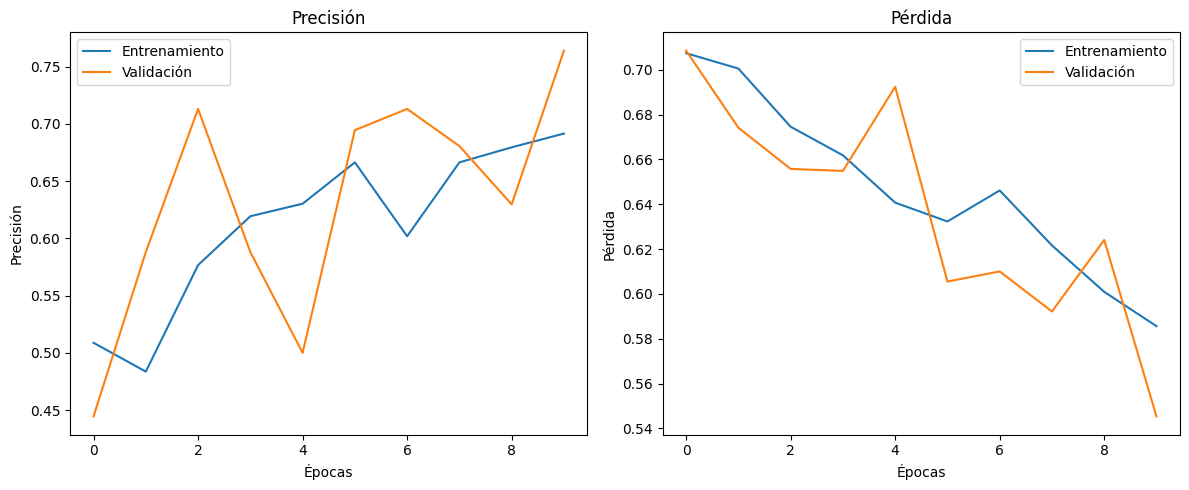

✅ Modelo guardado como modelo_gastos_perros.h5


In [4]:
# ✅ 1. IMPORTAR LIBRERÍAS NECESARIAS
import os
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
# ✅ 2. DEFINIR LA RUTA DONDE ESTÁ EL DATASET


# ✅ 3. PARÁMETROS DEL MODELO
tamaño_imagen = (150, 150)
batch_size = 32
epochs = 10


# ✅ 4. PREPROCESAMIENTO DE IMÁGENES CON AUMENTO Y NORMALIZACIÓN
datagen_train = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)

datagen_val = ImageDataGenerator(rescale=1./255)

# ✅ 5. GENERADORES DE DATOS (SIN 'subset')
train_generator = datagen_train.flow_from_directory(
    '/content/drive/MyDrive/practicasMachineL/DEEPLEARNING/GATOSPERROS/DATASET/dogscats/train',
    target_size=tamaño_imagen,
    batch_size=batch_size,
    class_mode='categorical',  # o 'binary' si haces el cambio explicado antes
    shuffle=True
)

val_generator = datagen_val.flow_from_directory(
    '/content/drive/MyDrive/practicasMachineL/DEEPLEARNING/GATOSPERROS/DATASET/dogscats/valid',
    target_size=tamaño_imagen,
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)

# ✅ 6. CREAR LA RED NEURONAL CONVOLUCIONAL
modelo = Sequential()

# Capa 1: convolución + pooling
modelo.add(Conv2D(32, (3, 3), activation='relu', input_shape=(tamaño_imagen[0], tamaño_imagen[1], 3)))
modelo.add(MaxPooling2D(pool_size=(2, 2)))

# Capa 2
modelo.add(Conv2D(64, (3, 3), activation='relu'))
modelo.add(MaxPooling2D(pool_size=(2, 2)))

# Capa 3
modelo.add(Conv2D(128, (3, 3), activation='relu'))
modelo.add(MaxPooling2D(pool_size=(2, 2)))

# Aplanar y conectar
modelo.add(Flatten())
modelo.add(Dense(512, activation='relu'))
modelo.add(Dropout(0.5))  # Regularización para evitar overfitting
modelo.add(Dense(train_generator.num_classes, activation='softmax'))  # Capa de salida

# ✅ 7. COMPILAR EL MODELO
modelo.compile(
    loss='categorical_crossentropy',  # Cambiar a 'binary_crossentropy' si hay 2 clases
    optimizer=Adam(learning_rate=0.0001),
    metrics=['accuracy']
)

# ✅ 8. ENTRENAR EL MODELO
historia = modelo.fit(
    train_generator,
    validation_data=val_generator,
    epochs=epochs
)

# ✅ 9. VISUALIZAR RESULTADOS
plt.figure(figsize=(12, 5))

# Precisión
plt.subplot(1, 2, 1)
plt.plot(historia.history['accuracy'], label='Entrenamiento')
plt.plot(historia.history['val_accuracy'], label='Validación')
plt.title('Precisión')
plt.xlabel('Épocas')
plt.ylabel('Precisión')
plt.legend()

# Pérdida
plt.subplot(1, 2, 2)
plt.plot(historia.history['loss'], label='Entrenamiento')
plt.plot(historia.history['val_loss'], label='Validación')
plt.title('Pérdida')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()

plt.tight_layout()
plt.show()


# ✅ 10. GUARDAR EL MODELO
modelo.save('/content/drive/MyDrive/practicasMachineL/DEEPLEARNING/GATOSPERROS/modelo_gastos_perros.h5')
print("✅ Modelo guardado como modelo_gastos_perros.h5")

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
import tensorflow as tf
from tensorflow.keras.preprocessing import image
import numpy as np

# ✅ Cargar el modelo previamente entrenado
modelo = tf.keras.models.load_model('/content/drive/MyDrive/practicasMachineL/DEEPLEARNING/GATOSPERROS/modelo_gastos_perros.h5')

# ✅ Definir etiquetas según el orden de las carpetas en el entrenamiento
clases = ['gatos', 'perros']  # Asegúrate de que esto coincida con las carpetas originales

# ✅ Cargar y preprocesar una imagen para predecir
def predecir_imagen(ruta_imagen):
    img = image.load_img(ruta_imagen, target_size=(150, 150))  # Usa el mismo tamaño usado en el entrenamiento
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    pred = modelo.predict(img_array)

    if pred.shape[1] == 1:  # Si usaste class_mode='binary'
        clase_predicha = clases[int(pred[0][0] > 0.5)]
        confianza = pred[0][0] if pred[0][0] > 0.5 else 1 - pred[0][0]
    else:  # Si usaste class_mode='categorical'
        clase_predicha = clases[np.argmax(pred)]
        confianza = np.max(pred)

    print(f'Predicción: {clase_predicha} ({confianza*100:.2f}% de confianza)')

# ✅ Usar la función
ruta = '/content/drive/MyDrive/practicasMachineL/DEEPLEARNING/GATOSPERROS/DATASET/dogscats/test/7.jpg'
predecir_imagen(ruta)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
Predicción: gatos (54.66% de confianza)
